# Weekly Demand: Common 26-Week Training, Four-Week Test, and 13-Week Forecast

In Google Colab, choose **Runtime > Run all** and upload `clean_supply_chain.csv`. All outputs and the generated report use English. No GPU is needed.

The target is **gross ordered units per Monday-Sunday week**, summed from `order_item_quantity` by `order_date`. Unique item rows contribute their quantities. All recorded order statuses are retained, matching the original demand target.

Every main model and SES receive exactly the **same 26 weekly training observations** at each origin. ARIMA, tree-based ML, and ANN are the three main families. SES and a last-observation naive forecast are benchmarks. Earlier four-week validation chooses settings within each family; it does not choose different history lengths.

The last **four complete weeks** form the test set. After evaluating four-step predictions issued at one origin, refit on the latest 26 complete weeks and forecast **13 weeks ahead**. This is a rolling 13-week horizon, not a named calendar quarter. Four-week test accuracy does not measure 13-week future accuracy.

The file, its outcomes, and the choice of a common 26-week window have already been explored. This is a retrospective comparison, not a completely blind test.

In [1]:
import importlib.util
import subprocess
import sys
packages = {'numpy': 'numpy', 'pandas': 'pandas', 'matplotlib': 'matplotlib',
            'scipy': 'scipy', 'sklearn': 'scikit-learn', 'statsmodels': 'statsmodels'}
missing = [name for module, name in packages.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '--quiet', *missing])
print('Required libraries are available.')

Required libraries are available.


In [2]:
from pathlib import Path
import os
DATA_FILENAME = 'clean_supply_chain.csv'
UPLOAD_NEW_FILE = False
if os.environ.get('DATA_CSV'):
    source = Path(os.environ['DATA_CSV'])
else:
    from google.colab import files
    source = Path('/content') / DATA_FILENAME
    if UPLOAD_NEW_FILE or not source.is_file():
        print('Upload exactly one clean_supply_chain.csv file.')
        uploaded = files.upload()
        names = [name for name in uploaded if name.lower().endswith('.csv')]
        if len(names) != 1:
            raise ValueError('Select exactly one CSV file, then rerun this cell.')
        source = Path(names[0]).resolve()
        del uploaded
assert source.is_file(), 'The input CSV does not exist.'
print('Input:', source.name)

Input: clean_supply_chain.csv


In [3]:
from pathlib import Path
from IPython.display import display
import base64
import hashlib
import html
import json
import platform
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import sklearn
import statsmodels
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.compose import TransformedTargetRegressor
from sklearn.exceptions import ConvergenceWarning
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.holtwinters import SimpleExpSmoothing

TRAIN_WEEKS, TEST_HORIZON, FUTURE_HORIZON, LAGS, SEED = 26, 4, 13, 4, 99
EXPORT_DIR = Path('weekly_demand_quarter_results')
EXPORT_DIR.mkdir(exist_ok=True)
COLORS = {'Actual': '#111111', 'ARIMA': '#0072B2', 'ML': '#7759c2', 'ANN': '#D55E00',
          'SES reference': '#009E73', 'Naive reference': '#b07c24', 'Neutral': '#64748b'}
STYLES = {'ARIMA': ('-.', '^'), 'ML': (':', 'v'), 'ANN': ('-', 's'), 'SES reference': ('--', 'D'), 'Naive reference': ('--', 'x')}
plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False, 'axes.spines.right': False})
versions = {'python': platform.python_version(), 'pandas': pd.__version__,
            'sklearn': sklearn.__version__, 'statsmodels': statsmodels.__version__}
source_hash = hashlib.sha256(source.read_bytes()).hexdigest()
print('Target: gross ordered units per complete Monday-Sunday week.')
print('Common train:', TRAIN_WEEKS, 'weeks | test:', TEST_HORIZON, 'weeks | future:', FUTURE_HORIZON, 'weeks')
print('Software:', versions)

Target: gross ordered units per complete Monday-Sunday week.
Common train: 26 weeks | test: 4 weeks | future: 13 weeks
Software: {'python': '3.13.18', 'pandas': '2.2.3', 'sklearn': '1.6.1', 'statsmodels': '0.15.0'}


## 1. Rebuild the demand target and show the common training period

Check unique item IDs and reconcile weekly quantity totals to the original item-level sum. Do not deduplicate by order ID. Exclude incomplete boundary weeks; the final source week has only three days for this file.

Retain complete earlier history for diagnostics and validation. At the test origin, all fitted models receive only the same latest 26 complete weeks, while the final four complete weeks remain excluded. The 26-week rule is fixed for every validation origin and the final refit.

Source item rows: 180519 | total recorded ordered units: 384079
Complete weeks: 2015-01-11 to 2018-01-28 (160 weeks)
Common 26-week train: 2017-07-09 to 2017-12-31
Four-week test: 2018-01-07 to 2018-01-28
Excluded incomplete boundary weeks:


,ordered_units,item_rows,distinct_orders,distinct_products,days_represented,Coverage
order_date,,,,,,
2015-01-04,1511,692,233,43,4,Excluded partial source week
2018-02-04,205,205,205,4,3,Excluded partial source week


Latest complete weeks:


,ordered_units,item_rows,distinct_orders,distinct_products,days_represented,Coverage
week_ending,,,,,,
2017-10-15,479,479,479,2,7,Complete source week
2017-10-22,480,480,480,2,7,Complete source week
2017-10-29,479,479,479,2,7,Complete source week
2017-11-05,480,480,480,3,7,Complete source week
2017-11-12,479,479,479,2,7,Complete source week
2017-11-19,480,480,480,3,7,Complete source week
2017-11-26,479,479,479,3,7,Complete source week
2017-12-03,480,480,480,3,7,Complete source week
2017-12-10,479,479,479,3,7,Complete source week


Largest training-only weekly decline: 2017-10-08 (-75.73%)


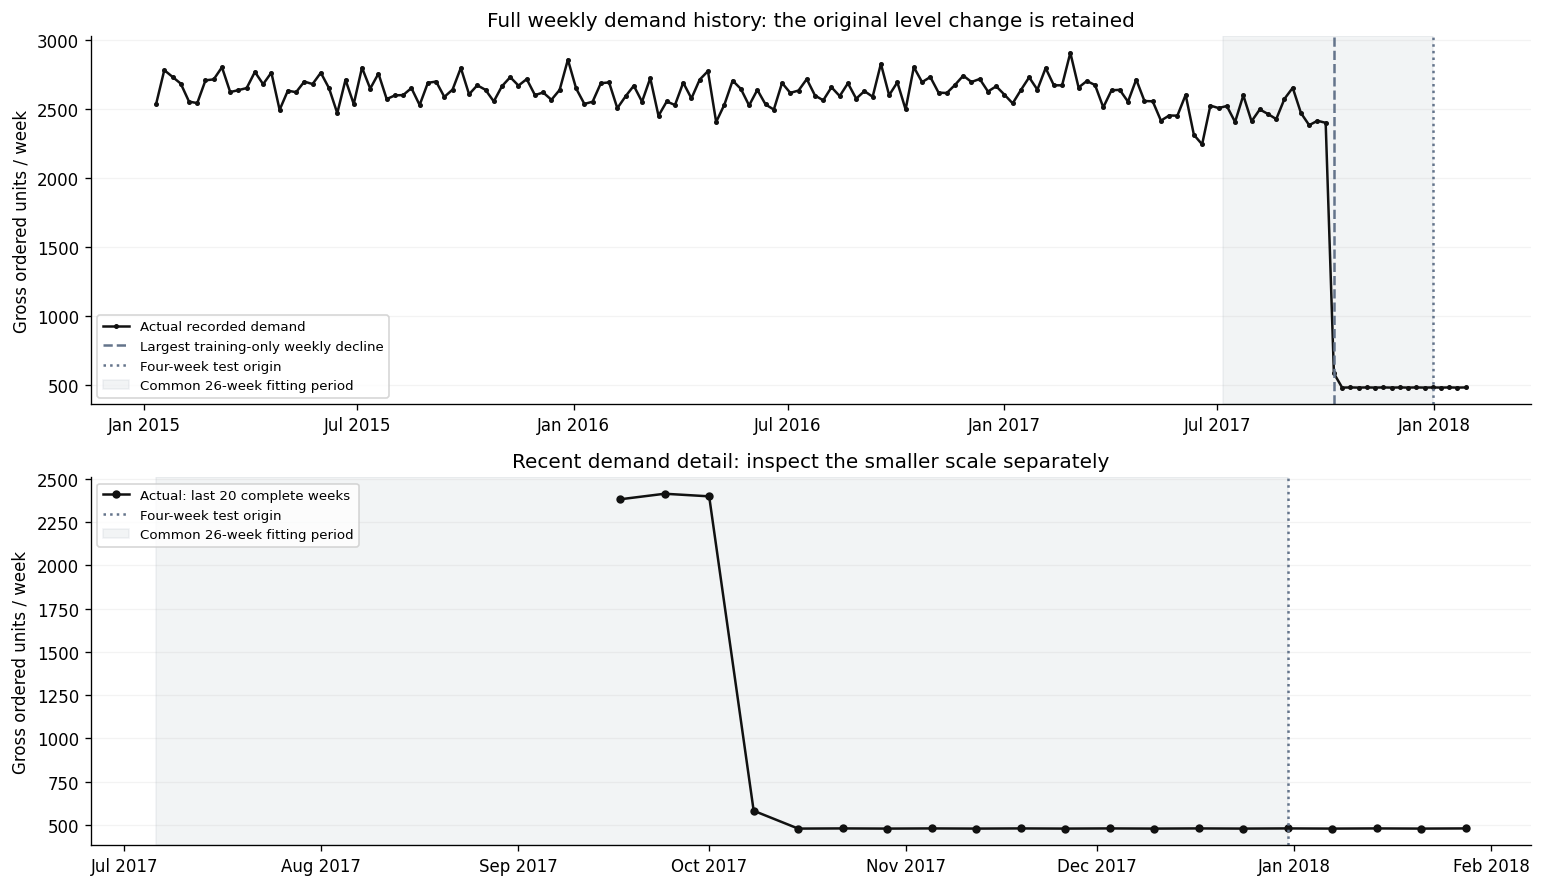

In [4]:
required = ['order_item_id', 'order_id', 'order_date', 'order_item_quantity', 'product_card_id', 'order_status']
df = pd.read_csv(source, usecols=required)
df['order_date'] = pd.to_datetime(df['order_date'], errors='raise')
df['order_item_quantity'] = pd.to_numeric(df['order_item_quantity'], errors='raise')
assert not df[required].isna().any().any()
assert df['order_item_id'].is_unique, 'Repeated item IDs need investigation.'
assert np.isfinite(df['order_item_quantity']).all() and df['order_item_quantity'].ge(0).all()
assert np.allclose(df['order_item_quantity'], np.round(df['order_item_quantity']))
df['order_day'] = df['order_date'].dt.normalize()
weekly = df.set_index('order_date').resample('W-SUN').agg(
    ordered_units=('order_item_quantity', 'sum'), item_rows=('order_item_id', 'size'),
    distinct_orders=('order_id', 'nunique'), distinct_products=('product_card_id', 'nunique'),
    days_represented=('order_day', 'nunique'))
first_day, last_day = df['order_day'].min(), df['order_day'].max()
eligible = ((weekly.index-pd.Timedelta(days=6) >= first_day) & (weekly.index <= last_day))
weekly['Coverage'] = np.where(eligible, 'Complete source week', 'Excluded partial source week')
assert np.isclose(weekly['ordered_units'].sum(), df['order_item_quantity'].sum())
assert weekly['item_rows'].sum() == len(df)
data = weekly.loc[eligible].copy().asfreq('W-SUN')
data.index.name = 'week_ending'
assert data.notna().all().all() and data['days_represented'].eq(7).all()
y = data['ordered_units'].astype(float)
development, test = y.iloc[:-TEST_HORIZON], y.iloc[-TEST_HORIZON:]
train = development.iloc[-TRAIN_WEEKS:].copy()
assert len(development) >= 104 and len(train) == TRAIN_WEEKS and len(test) == TEST_HORIZON
assert train.index[-1] < test.index[0]
weekly.to_csv(EXPORT_DIR/'all_weekly_demand.csv', index_label='week_ending')
df.groupby('order_status').agg(item_rows=('order_item_id','size'), gross_units=('order_item_quantity','sum')).to_csv(EXPORT_DIR/'order_status_audit.csv')
print('Source item rows:', len(df), '| total recorded ordered units:', int(df['order_item_quantity'].sum()))
print(f'Complete weeks: {y.index[0].date()} to {y.index[-1].date()} ({len(y)} weeks)')
print(f'Common 26-week train: {train.index[0].date()} to {train.index[-1].date()}')
print(f'Four-week test: {test.index[0].date()} to {test.index[-1].date()}')
train.rename('Gross ordered units').to_csv(EXPORT_DIR/'common_test_training_data.csv', index_label='week_ending')
print('Excluded incomplete boundary weeks:')
display(weekly.loc[~eligible])
print('Latest complete weeks:')
display(data.tail(16))
relative_change = development.pct_change()
largest_drop = relative_change.idxmin()
print('Largest training-only weekly decline:', largest_drop.date(), f'({100*relative_change.loc[largest_drop]:.2f}%)')

fig, axes = plt.subplots(2, 1, figsize=(13, 7.5))
axes[0].plot(y.index, y, color=COLORS['Actual'], marker='o', ms=2, label='Actual recorded demand')
axes[0].axvline(largest_drop, color=COLORS['Neutral'], linestyle='--', label='Largest training-only weekly decline')
axes[1].plot(y.index[-20:], y.iloc[-20:], color=COLORS['Actual'], marker='o', ms=4, label='Actual: last 20 complete weeks')
for ax in axes:
    ax.axvline(train.index[-1], color=COLORS['Neutral'], linestyle=':', label='Four-week test origin')
    ax.axvspan(train.index[0]-pd.Timedelta(days=3), train.index[-1], color=COLORS['Neutral'], alpha=.08, label='Common 26-week fitting period')
    ax.set_ylabel('Gross ordered units / week')
    ax.grid(axis='y', alpha=.15)
    ax.legend(fontsize=8)
axes[0].set_title('Full weekly demand history: the original level change is retained')
axes[0].xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1,7]))
axes[0].xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
axes[1].set_title('Recent demand detail: inspect the smaller scale separately')
axes[1].xaxis.set_major_locator(mdates.MonthLocator())
axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
fig.tight_layout()
fig.savefig(EXPORT_DIR/'01_weekly_demand_history.png', dpi=160, bbox_inches='tight')
plt.show()

## 2. Compare three families on the same 26-week inputs

Compare ARIMA orders (0,0,0), (1,0,0), (0,0,1), and (0,1,1); two Random Forest settings and HistGradientBoosting; and two small regularized ANN/MLP settings. Every candidate uses exactly 26 weeks. SES and naive forecasts are references.

ML and ANN share four lags, two/four-week means, four-week standard deviation, and known annual calendar sine/cosine features. This leaves **22 supervised examples** from the 26-week window. ANN input/target scalers are fitted only on these training examples. Calendar values are known in advance; future demand is not.

After the origin, recursive features insert the model's own previous predictions. Forecasts are nonnegative and scored without rounding. No artificial variation or offsets are added. A flat forecast may remain appropriate for the recent stable recorded demand.

In [5]:
BASE_CANDIDATES = [
    {'id': 'ARIMA_000', 'family': 'ARIMA', 'order': (0, 0, 0)},
    {'id': 'ARIMA_100', 'family': 'ARIMA', 'order': (1, 0, 0)},
    {'id': 'ARIMA_001', 'family': 'ARIMA', 'order': (0, 0, 1)},
    {'id': 'ARIMA_011', 'family': 'ARIMA', 'order': (0, 1, 1)},
    {'id': 'RF_shallow', 'family': 'ML', 'algorithm': 'Random Forest', 'depth': 4, 'leaf': 5},
    {'id': 'RF_flexible', 'family': 'ML', 'algorithm': 'Random Forest', 'depth': None, 'leaf': 3},
    {'id': 'HGB_regularized', 'family': 'ML', 'algorithm': 'HistGradientBoosting'},
    {'id': 'ANN_regularized', 'family': 'ANN', 'layers': (16, 8), 'alpha': 10.0},
    {'id': 'ANN_small', 'family': 'ANN', 'layers': (8,), 'alpha': 1.0},
    {'id': 'SES_reference', 'family': 'SES reference'},
]
CANDIDATES = []
for base in BASE_CANDIDATES:
    for window in [TRAIN_WEEKS]:
        CANDIDATES.append({**base, 'window': window, 'id': base['id']+'_W'+str(window or 'all')})
CANDIDATES.append({'id': 'Naive', 'family': 'Naive reference', 'window': TRAIN_WEEKS})
candidate_map = {candidate['id']: candidate for candidate in CANDIDATES}
(EXPORT_DIR / 'candidate_configurations.json').write_text(json.dumps(CANDIDATES, indent=2), encoding='utf-8')

def short_label(spec):
    if spec['family'] == 'ARIMA':
        return f'ARIMA{spec["order"]}'
    if spec['family'] == 'ML':
        return spec['algorithm']
    if spec['family'] == 'ANN':
        return 'ANN'
    return spec['family']

def features(history, date):
    h = np.asarray(history, dtype=float)
    assert len(h) >= LAGS
    phase = 2*np.pi*(date.dayofyear-1)/365.25
    return np.r_[h[-LAGS:][::-1], h[-2:].mean(), h[-4:].mean(),
                 h[-4:].std(ddof=0), np.sin(phase), np.cos(phase)]

def fit_predict(spec, history, horizon=TEST_HORIZON):
    assert spec['window'] == TRAIN_WEEKS and len(history) >= TRAIN_WEEKS
    history = history.iloc[-TRAIN_WEEKS:]
    assert len(history) == TRAIN_WEEKS
    values = history.to_numpy(dtype=float)
    dates = pd.date_range(history.index[-1]+pd.Timedelta(weeks=1), periods=horizon, freq='W-SUN')
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        if spec['family'] == 'ARIMA':
            fitted = ARIMA(values, order=spec['order'], trend='c' if spec['order'][1] == 0 else 'n').fit()
            if not fitted.mle_retvals.get('converged', False):
                raise RuntimeError('ARIMA optimizer did not converge.')
            prediction = fitted.forecast(horizon)
        elif spec['family'] == 'Naive reference':
            prediction = np.repeat(values[-1], horizon)
        elif spec['family'] == 'SES reference':
            fitted = SimpleExpSmoothing(values, initialization_method='estimated').fit()
            if not fitted.mle_retvals.get('success', True):
                raise RuntimeError('SES optimizer did not converge.')
            prediction = fitted.forecast(horizon)
        else:
            X = np.asarray([features(values[:i], history.index[i]) for i in range(LAGS, len(values))])
            target = values[LAGS:]
            if spec['family'] == 'ANN':
                fitted = TransformedTargetRegressor(
                    regressor=make_pipeline(StandardScaler(), MLPRegressor(hidden_layer_sizes=spec['layers'],
                        alpha=spec['alpha'], activation='relu', solver='lbfgs', max_iter=2000, random_state=SEED)),
                    transformer=StandardScaler())
            elif spec['algorithm'] == 'Random Forest':
                fitted = RandomForestRegressor(n_estimators=200, max_depth=spec['depth'],
                    min_samples_leaf=spec['leaf'], random_state=SEED, n_jobs=1)
            else:
                fitted = HistGradientBoostingRegressor(max_iter=100, learning_rate=0.05, max_leaf_nodes=7,
                    min_samples_leaf=10, l2_regularization=10.0, early_stopping=False, random_state=SEED)
            fitted.fit(X, target)
            recursive_history, prediction = list(values), []
            for date in dates:
                point = max(0.0, float(fitted.predict(features(recursive_history, date).reshape(1, -1))[0]))
                prediction.append(point)
                recursive_history.append(point)
    messages = [str(w.message) for w in caught]
    if any(issubclass(w.category, ConvergenceWarning) for w in caught):
        raise RuntimeError('Optimizer convergence warning: ' + '; '.join(messages))
    prediction = np.maximum(0.0, np.asarray(prediction, dtype=float))
    if prediction.shape != (horizon,) or not np.isfinite(prediction).all():
        raise RuntimeError('Invalid forecast output.')
    return prediction, messages

def window_label(spec):
    return 'last observation' if spec['family'] == 'Naive reference' else str(spec.get('window') or 'all')+' weeks'

In [6]:
def scores(actual, predicted):
    actual, predicted = np.asarray(actual, dtype=float), np.asarray(predicted, dtype=float)
    assert actual.shape == predicted.shape
    error = predicted-actual
    nonzero = actual != 0
    return {'MAE (units)': float(np.abs(error).mean()),
            'RMSE (units)': float(np.sqrt(np.mean(error**2))),
            'MAPE (%)': float(100*np.abs(error[nonzero]/actual[nonzero]).mean()) if nonzero.any() else np.nan,
            'WAPE (%)': float(100*np.abs(error).sum()/np.abs(actual).sum()) if np.abs(actual).sum() else np.nan,
            'Bias (units)': float(error.mean())}

## 3. Choose configurations using earlier four-week validation

Use six non-overlapping four-week validation blocks within the latest 24 development weeks, all before the final test. At each origin, every model receives exactly the same preceding 26 weekly observations. Validation includes the historical demand shift.

Choose one configuration per family by mean four-week validation MAE, requiring convergence in all folds. These settings will be used for both the four-week test and the 13-week projection. No 13-week accuracy is claimed from this four-week selection procedure.

In [7]:
origins = list(range(len(development)-6*TEST_HORIZON, len(development)-TEST_HORIZON+1, TEST_HORIZON))
cv_rows, cv_predictions, estimation_notes = [], [], []
for fold, origin in enumerate(origins, start=1):
    fold_train = development.iloc[origin-TRAIN_WEEKS:origin]
    validation = development.iloc[origin:origin+TEST_HORIZON]
    assert len(fold_train) == TRAIN_WEEKS
    assert fold_train.index[-1] < validation.index[0] and len(validation) == TEST_HORIZON
    print(f'Validation fold {fold}/{len(origins)}: origin {fold_train.index[-1].date()}')
    for spec in CANDIDATES:
        entry = {'Candidate': spec['id'], 'Family': spec['family'], 'Origin': str(fold_train.index[-1].date()), 'Train start': str(fold_train.index[0].date()), 'Train weeks': len(fold_train)}
        try:
            pred, messages = fit_predict(spec, fold_train)
            cv_rows.append({**entry, 'Valid': True, **scores(validation, pred)})
            estimation_notes.extend({**entry, 'Message': message} for message in messages)
            cv_predictions.extend({**entry, 'Horizon': h, 'Week ending': str(date.date()),
                'Actual': float(actual), 'Forecast': float(point)}
                for h, (date, actual, point) in enumerate(zip(validation.index, validation, pred), start=1))
        except RuntimeError as error:
            cv_rows.append({**entry, 'Valid': False})
            estimation_notes.append({**entry, 'Message': str(error)})
cv_folds = pd.DataFrame(cv_rows)
cv_summary = cv_folds.groupby(['Candidate', 'Family']).agg(
    Validation_MAE_units=('MAE (units)', 'mean'), Validation_MAE_SD=('MAE (units)', 'std'),
    Validation_MAPE_percent=('MAPE (%)', 'mean'), Valid_folds=('Valid', 'sum'), Total_folds=('Valid', 'size')).reset_index()
cv_summary['Eligible'] = cv_summary['Valid_folds'].eq(len(origins)) & cv_summary['Total_folds'].eq(len(origins))
cv_summary = cv_summary.sort_values(['Eligible', 'Validation_MAE_units', 'Candidate'], ascending=[False, True, True])
selected = {}
for family in ['ARIMA', 'ML', 'ANN', 'SES reference', 'Naive reference']:
    options = cv_summary.loc[cv_summary['Eligible'] & cv_summary['Family'].eq(family)]
    if options.empty:
        raise RuntimeError(f'No valid configuration for {family}; inspect estimation_notes.csv.')
    selected[family] = options.iloc[0]['Candidate']
selected_specs = {family: candidate_map[name] for family, name in selected.items()}
selected_validation = cv_summary.set_index('Candidate').loc[list(selected.values())].copy()
cv_best_main = selected_validation.loc[selected_validation['Family'].isin(['ARIMA', 'ML', 'ANN']), 'Validation_MAE_units'].idxmin()
cv_best_overall = selected_validation['Validation_MAE_units'].idxmin()
display(cv_summary.round(6))
print('Selected configurations:', selected)
print('Lowest validation MAE among the three main families:', cv_best_main)
print('Lowest validation MAE including references:', cv_best_overall)
cv_folds.to_csv(EXPORT_DIR / 'validation_fold_scores.csv', index=False)
cv_summary.to_csv(EXPORT_DIR / 'all_candidate_validation_scores.csv', index=False)
selected_validation.to_csv(EXPORT_DIR / 'selected_configuration_validation.csv')
pd.DataFrame(cv_predictions).to_csv(EXPORT_DIR / 'validation_predictions.csv', index=False)
pd.DataFrame(estimation_notes, columns=['Candidate', 'Family', 'Origin', 'Message']).to_csv(EXPORT_DIR / 'estimation_notes.csv', index=False)
pd.DataFrame(cv_rows)[['Origin','Train start','Train weeks']].drop_duplicates().to_csv(EXPORT_DIR/'validation_training_windows.csv', index=False)

Validation fold 1/6: origin 2017-07-16
Validation fold 2/6: origin 2017-08-13
Validation fold 3/6: origin 2017-09-10
Validation fold 4/6: origin 2017-10-08
Validation fold 5/6: origin 2017-11-05
Validation fold 6/6: origin 2017-12-03


,Candidate,Family,Validation_MAE_units,Validation_MAE_SD,Validation_MAPE_percent,Valid_folds,Total_folds,Eligible
7,Naive,Naive reference,133.625000,197.202799,18.601602,6,6,True
4,ARIMA_011_W26,ARIMA,196.652870,253.473732,31.530201,6,6,True
1,ANN_small_W26,ANN,217.632970,235.767571,34.746393,6,6,True
10,SES_reference_W26,SES reference,245.212388,331.228545,41.721208,6,6,True
8,RF_flexible_W26,ML,418.787976,605.015355,78.743055,6,6,True
5,ARIMA_100_W26,ARIMA,464.653755,561.752916,86.644550,6,6,True
9,RF_shallow_W26,ML,520.296923,642.332271,100.182652,6,6,True
0,ANN_regularized_W26,ANN,563.233510,680.871736,108.439043,6,6,True
6,HGB_regularized_W26,ML,607.270623,653.113485,117.879036,6,6,True
3,ARIMA_001_W26,ARIMA,837.923579,690.614635,164.113122,6,6,True


Selected configurations: {'ARIMA': 'ARIMA_011_W26', 'ML': 'RF_flexible_W26', 'ANN': 'ANN_small_W26', 'SES reference': 'SES_reference_W26', 'Naive reference': 'Naive'}
Lowest validation MAE among the three main families: ARIMA_011_W26
Lowest validation MAE including references: Naive


## 4. Evaluate four held-out weeks using the common train

All fitted models use the same 26 weekly observations, with identical start and end dates. Forecast all four test weeks at one origin; do not update with test actuals. A naive benchmark uses the last value from that same history.

Test MAE describes this four-week block. Small differences and stable test demand do not establish universal superiority or long-horizon performance. The previously examined test is not a fresh independent confirmation.

ANN holdout estimation note: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.


,Selected candidate,MAE (units),RMSE (units),MAPE (%),WAPE (%),Bias (units)
Family,,,,,,
SES reference,SES_reference_W26,0.500000,0.707107,0.104384,0.104275,0.500000
Naive reference,Naive,0.500000,0.707107,0.104384,0.104275,0.500000
ARIMA,ARIMA_011_W26,0.530029,0.728650,0.110647,0.110538,0.530029
ML,RF_flexible_W26,2.008085,2.059350,0.418839,0.418787,2.008085
ANN,ANN_small_W26,75.253851,81.432685,15.691310,15.694234,75.253851


Lowest observed holdout MAE, main families: ARIMA
Lowest observed holdout MAE, including references: SES reference, Naive reference


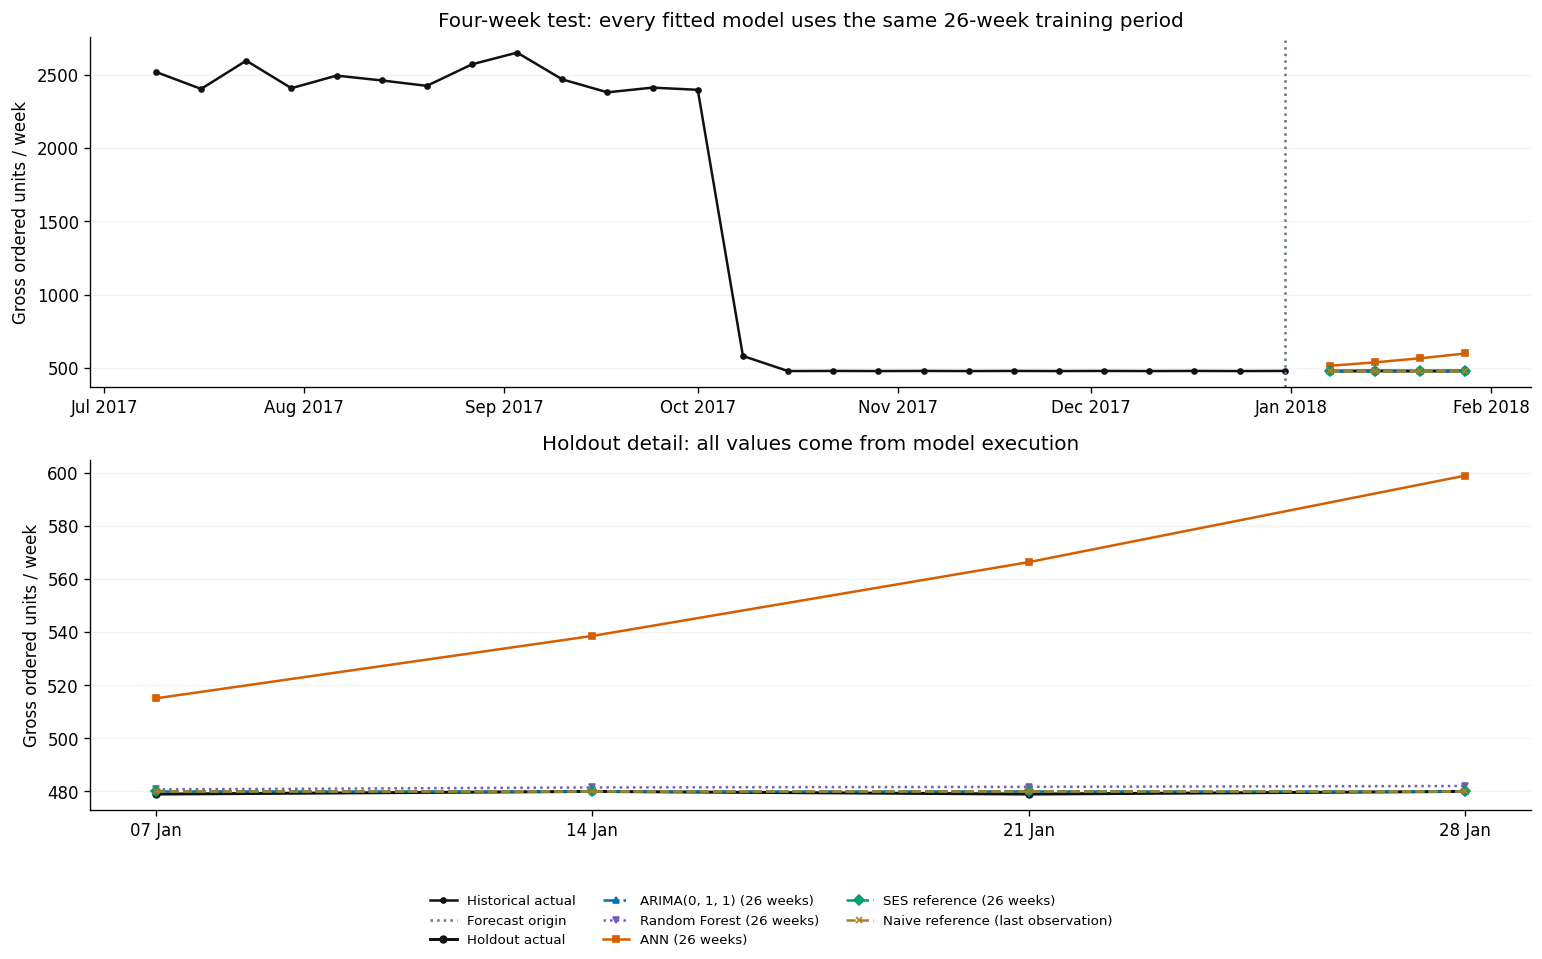

,Family,Train start,Train end,Train weeks,Forecast steps
0,ARIMA,2017-07-09,2017-12-31,26,4
1,ML,2017-07-09,2017-12-31,26,4
2,ANN,2017-07-09,2017-12-31,26,4
3,SES reference,2017-07-09,2017-12-31,26,4
4,Naive reference,2017-07-09,2017-12-31,26,4


In [8]:
predictions, test_rows = {}, []
for family, spec in selected_specs.items():
    predictions[family], messages = fit_predict(spec, train)
    for message in messages:
        print(f'{family} holdout estimation note:', message)
    test_rows.append({'Family': family, 'Selected candidate': spec['id'], **scores(test, predictions[family])})
test_scores = pd.DataFrame(test_rows).set_index('Family').sort_values('MAE (units)')
test_best_main = test_scores.loc[test_scores.index.isin(['ARIMA', 'ML', 'ANN']), 'MAE (units)'].idxmin()
best_error = test_scores['MAE (units)'].min()
test_leaders = test_scores.index[np.isclose(test_scores['MAE (units)'], best_error, rtol=0, atol=1e-6)].tolist()
test_best_overall = ', '.join(test_leaders)
display(test_scores.round(6))
print('Lowest observed holdout MAE, main families:', test_best_main)
print('Lowest observed holdout MAE, including references:', test_best_overall)
holdout = pd.DataFrame(predictions, index=test.index)
holdout.insert(0, 'Actual demand units', test)
holdout.to_csv(EXPORT_DIR / 'holdout_predictions.csv', index_label='week_ending')
test_scores.to_csv(EXPORT_DIR / 'holdout_model_comparison.csv')

fig, axes = plt.subplots(2, 1, figsize=(13, 8))
axes[0].plot(train.index[-26:], train.iloc[-26:], color=COLORS['Actual'], marker='o', ms=3, label='Historical actual')
axes[0].axvline(train.index[-1], color=COLORS['Neutral'], linestyle=':', label='Forecast origin')
for ax in axes:
    ax.plot(test.index, test, color=COLORS['Actual'], marker='o', ms=4, linewidth=1.8, label='Holdout actual')
    for family, pred in predictions.items():
        style, marker = STYLES[family]
        ax.plot(test.index, pred, color=COLORS[family], linestyle=style, marker=marker, ms=4,
                label=short_label(selected_specs[family])+' ('+window_label(selected_specs[family])+')')
    ax.set_ylabel('Gross ordered units / week')
    ax.grid(axis='y', alpha=0.15)
axes[0].set_title('Four-week test: every fitted model uses the same 26-week training period')
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, fontsize=8, ncol=3, loc='lower center', frameon=False)
axes[0].xaxis.set_major_locator(mdates.MonthLocator())
axes[0].xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
axes[1].set_title('Holdout detail: all values come from model execution')
axes[1].xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.SU, interval=1))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))
fig.tight_layout(rect=[0, 0.10, 1, 1])
fig.savefig(EXPORT_DIR / '02_four_week_test_comparison.png', dpi=180, bbox_inches='tight')
plt.show()
comparison_design = pd.DataFrame([{'Family':family,'Train start':str(train.index[0].date()),'Train end':str(train.index[-1].date()),'Train weeks':len(train),'Forecast steps':TEST_HORIZON} for family in selected_specs])
display(comparison_design)
comparison_design.to_csv(EXPORT_DIR/'common_test_design.csv', index=False)

## 5. Refit on a common 26 weeks and forecast 13 weeks ahead

Move the origin to the latest complete Sunday. Every model is refitted on the same latest 26 weekly values, now including the four observed test weeks. Keep the configurations selected by earlier validation. Issue 13 forecasts without future actual updates.

The 13-week span is a rolling quarter equivalent. It is not the next named calendar quarter. The file lacks complete actual quantities for these future weeks, so the four-week test scores must not be labeled as quarterly forecast accuracy. Partial source-week quantities remain a separate diagnostic. No calibrated prediction intervals are claimed.

Common final 26-week train: 2017-08-06 to 2018-01-28
ML final estimation note: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
ANN final estimation note: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.


,ARIMA,ML,ANN,SES reference,Naive reference
week_ending,,,,,
2018-02-04,480.067804,479.771131,479.709131,480.0,480.0
2018-02-11,480.067804,481.118119,480.301398,480.0,480.0
2018-02-18,480.067804,481.558369,480.971182,480.0,480.0
2018-02-25,480.067804,482.535036,481.709331,480.0,480.0
2018-03-04,480.067804,486.425925,482.503161,480.0,480.0
2018-03-11,480.067804,486.553008,483.343072,480.0,480.0
2018-03-18,480.067804,486.553008,484.215801,480.0,480.0
2018-03-25,480.067804,517.861966,485.108705,480.0,480.0
2018-04-01,480.067804,850.283591,486.008850,480.0,480.0


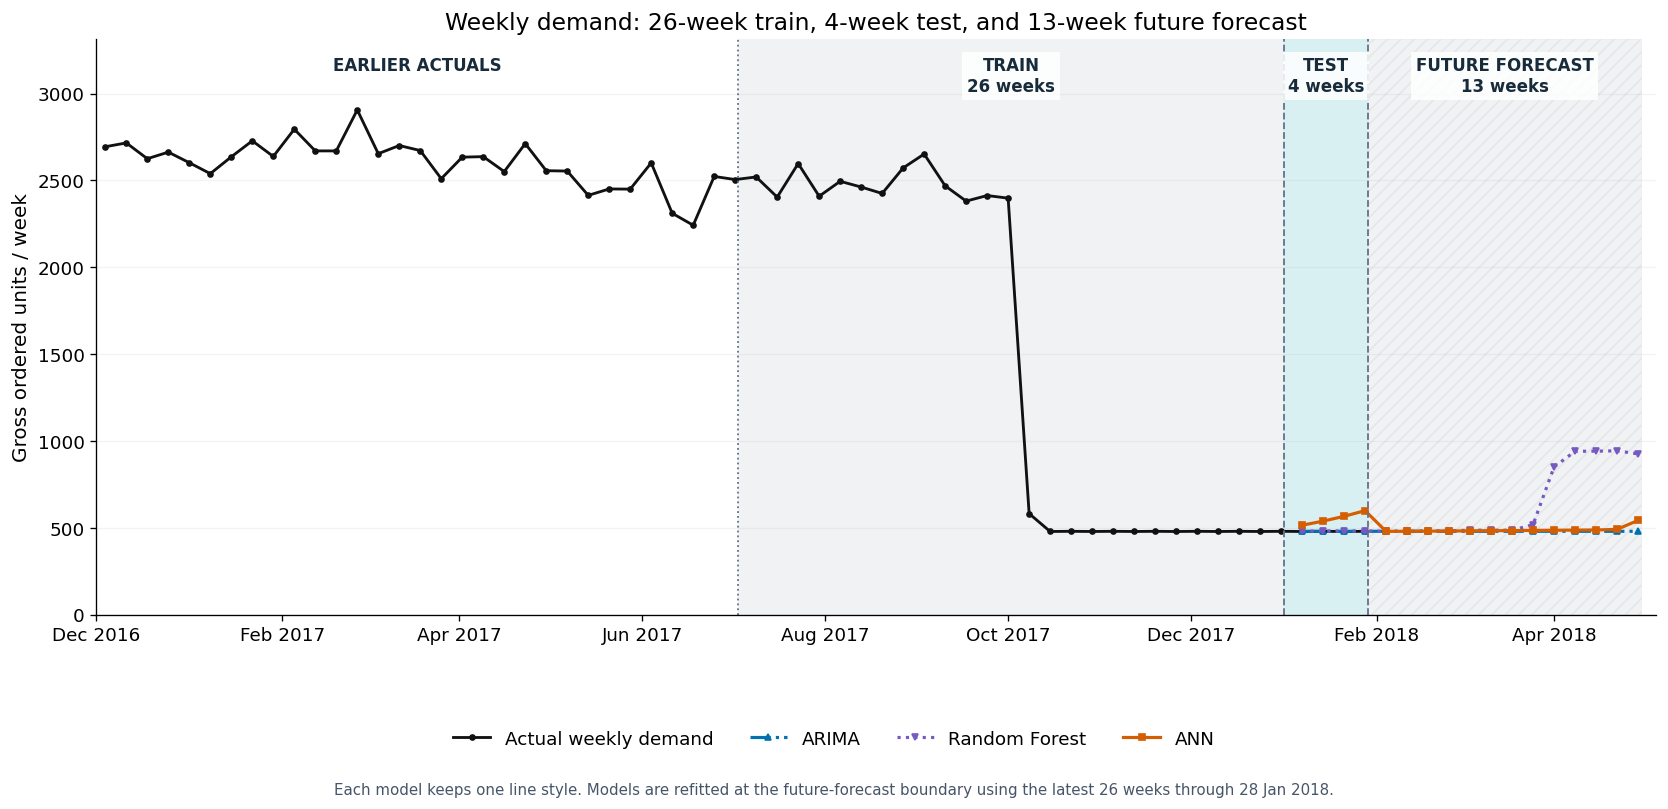

13-week forecast totals, in units:


,Forecast total units
ARIMA,6240.881450
ML,8504.028506
ANN,6352.363690
SES reference,6240.000000
Naive reference,6240.000000


In [9]:
future_index = pd.date_range(y.index[-1]+pd.Timedelta(weeks=1), periods=FUTURE_HORIZON, freq='W-SUN')
future_train = y.iloc[-TRAIN_WEEKS:].copy()
assert len(future_train) == TRAIN_WEEKS
future_train.rename('Gross ordered units').to_csv(EXPORT_DIR/'common_future_training_data.csv', index_label='week_ending')
print(f'Common final 26-week train: {future_train.index[0].date()} to {future_train.index[-1].date()}')
future_predictions = {}
for family, spec in selected_specs.items():
    future_predictions[family], messages = fit_predict(spec, future_train, horizon=FUTURE_HORIZON)
    for message in messages:
        print(f'{family} final estimation note:', message)
future = pd.DataFrame(future_predictions, index=future_index)
future.index.name = 'week_ending'
display(future.round(6))
future.to_csv(EXPORT_DIR / 'future_13week_demand_forecast.csv')


DISPLAY_START = pd.Timestamp('2016-12-01')
visible_history = y.loc[y.index >= DISPLAY_START]
train_start = train.index[0]-pd.Timedelta(days=6)
test_start = test.index[0]-pd.Timedelta(days=6)
future_start = future_index[0]-pd.Timedelta(days=6)
future_end = future_index[-1]+pd.Timedelta(days=1)
fig, ax = plt.subplots(figsize=(14, 6.8))
ax.axvspan(train_start, test_start, facecolor=COLORS['Neutral'], alpha=.09, zorder=0)
ax.axvspan(test_start, future_start, facecolor='#18a6b8', alpha=.16, zorder=0)
ax.axvspan(future_start, future_end, facecolor=COLORS['Neutral'], edgecolor=COLORS['Neutral'],
           alpha=.09, hatch='///', linewidth=.5, zorder=0)
ax.plot(visible_history.index, visible_history, color=COLORS['Actual'], marker='o', ms=3,
        linewidth=1.7, label='Actual weekly demand')
model_dates = test.index.append(future_index)
model_labels = {'ARIMA':'ARIMA','ML':'Random Forest','ANN':'ANN'}
for family in ['ARIMA','ML','ANN']:
    style, marker = STYLES[family]
    model_values = np.r_[predictions[family],future_predictions[family]]
    ax.plot(model_dates,model_values,color=COLORS[family],linestyle=style,marker=marker,
            ms=4,linewidth=1.9,label=model_labels[family])
for boundary, style in [(train_start,':'), (test_start,'--'), (future_start,'--')]:
    ax.axvline(boundary,color=COLORS['Neutral'],linestyle=style,linewidth=1.1)
for left,right,label in [
    (DISPLAY_START,train_start,'EARLIER ACTUALS'),
    (train_start,test_start,'TRAIN\n26 weeks'),
    (test_start,future_start,'TEST\n4 weeks'),
    (future_start,future_end,'FUTURE FORECAST\n13 weeks')]:
    ax.text(left+(right-left)/2,.97,label,transform=ax.get_xaxis_transform(),
            ha='center',va='top',fontsize=10,fontweight='bold',color='#172b3a',
            bbox=dict(facecolor='white',edgecolor='none',alpha=.85,pad=3))
ax.set(title='Weekly demand: 26-week train, 4-week test, and 13-week future forecast',
       ylabel='Gross ordered units / week')
ax.set_xlim(DISPLAY_START,future_end+pd.Timedelta(days=5))
ax.set_ylim(0,1.14*max(visible_history.max(),future.to_numpy().max(),holdout.iloc[:,1:].to_numpy().max()))
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax.tick_params(axis='both',labelsize=11)
ax.title.set_fontsize(14)
ax.yaxis.label.set_size(12)
ax.grid(axis='y',alpha=.15)
handles,labels=ax.get_legend_handles_labels()
fig.legend(handles,labels,fontsize=11,ncol=4,loc='lower center',bbox_to_anchor=(.5,.055),frameon=False)
fig.text(.5,.015,'Each model keeps one line style. Models are refitted at the future-forecast boundary '
         'using the latest 26 weeks through 28 Jan 2018.',
         ha='center',va='bottom',fontsize=9,color='#475569')
fig.tight_layout(rect=[0,.18,1,1])
fig.savefig(EXPORT_DIR/'03_future_13week_demand.png',dpi=180,bbox_inches='tight')
plt.show()



print('13-week forecast totals, in units:')
display(future.sum().rename('Forecast total units').to_frame())
future.sum().rename('Forecast total units').rename_axis('Family').to_csv(EXPORT_DIR/'future_13week_totals.csv')

## 6. English report and reproducibility

The report is generated from this run. It distinguishes common 26-week fitting inputs, four-week test accuracy, and 13-week future projections. Exact date ranges, candidate scores, and individual weekly forecasts are exported.

In [10]:
NEWLINE = chr(10)
def md_table(frame, decimals=5):
    t = frame.reset_index()
    lines = ['| '+' | '.join(map(str, t.columns))+' |', '| '+' | '.join(['---']*len(t.columns))+' |']
    for row in t.itertuples(index=False, name=None):
        lines.append('| '+' | '.join(f'{value:.{decimals}f}' if isinstance(value, (float, np.floating)) else str(value) for value in row)+' |')
    return NEWLINE.join(lines)



future_behavior = pd.DataFrame({'First week units':future.iloc[0], 'Last week units':future.iloc[-1],
    'Minimum units':future.min(), 'Maximum units':future.max()}).rename_axis('Family')
future_behavior.to_csv(EXPORT_DIR/'future_13week_behavior.csv')
sections = [
    ('Executive summary',
     f'This study compares ARIMA, tree-based ML, and ANN using a common {TRAIN_WEEKS}-week fitting window. '
     f'The lowest main-family mean four-week validation MAE belongs to {cv_best_main}. '
     f'The lowest observed main-family four-week test MAE belongs to {test_best_main} '
     f'({test_scores.loc[test_best_main,"MAE (units)"]:.4f} units; MAPE {test_scores.loc[test_best_main,"MAPE (%)"]:.4f}%). '
     f'Test MAE leaders including benchmarks, allowing numerical differences within 0.000001 units, are {test_best_overall}. '
     f'A separate {FUTURE_HORIZON}-week projection illustrates future model behavior. Its accuracy is unknown.'),
    ('Target, source coverage, and structural change',
     f'The source contains {len(df):,} unique item rows and {int(df["order_item_quantity"].sum()):,} recorded ordered units. '
     'Weekly demand sums order_item_quantity by order_date in Monday-Sunday weeks, retaining all recorded statuses. '
     'This is gross recorded quantity, not net fulfilled demand or an order count. '
     'Different item rows from one order retain their separate quantities. '
     f'There are {len(y)} complete weeks from {y.index[0].date()} to {y.index[-1].date()}. '
     'Partial source-boundary weeks are excluded without scaling or inventing quantities. '
     f'The largest development-period weekly percentage decline is {largest_drop.date()} '
     f'({100*relative_change.loc[largest_drop]:.2f}%). Original values are preserved. '
     'The recent near-constant quantities and the earlier high-volume period represent different recorded patterns. '
     'The file alone cannot establish whether the change reflects demand, product coverage, or a recording process.'),
    ('Common training design',
     f'The development period has {len(development)} complete weeks, but each fitting call receives exactly {TRAIN_WEEKS} observations. '
     f'For the final four-week test, every fitted model receives {train.index[0].date()} to {train.index[-1].date()}. '
     f'The test week endings are {test.index[0].date()} to {test.index[-1].date()}. '
     'Earlier development history supports validation and diagnostics, not an additional history advantage for any family. '
     'The common 26-week rule was chosen after earlier exploratory comparisons. It is not a universal optimum. '
     'A naive benchmark naturally uses only the last observation of that same window.'),
    ('Models and earlier validation',
     'ARIMA candidates are (0,0,0), (1,0,0), (0,0,1), and (0,1,1). '
     'ML compares two Random Forest settings and HistGradientBoosting. ANN compares two small regularized MLPs. '
     'SES and naive forecasts are benchmarks. Each model receives the same 26-week input at every origin. '
     'ML and ANN share four lags, two/four-week means, four-week standard deviation, and known annual calendar sine/cosine values. '
     'This leaves 22 supervised training examples. Input and target scalers for ANN are fitted only within its training window. '
     'Six non-overlapping four-week validation blocks in the last 24 development weeks choose settings within each family by mean MAE. '
     'All six fitting windows are 26 weeks long, and failed convergence excludes a candidate. '
     'After the origin, recursive features use earlier predictions rather than future actuals. Forecasts are nonnegative and scored unrounded. '
     'The same selected settings are later projected for 13 weeks; they have not been selected or validated for a 13-week horizon.'),
    ('Four-week test results',
     f'The lowest observed main-family test MAE belongs to {test_best_main}. '
     f'The benchmark-inclusive MAE leaders within a 0.000001-unit tolerance are {test_best_overall}. '
     f'Actual test demand ranges from {test.min():.0f} to {test.max():.0f} units per week. '
     'Such a stable four-observation test can favor simple level forecasts. '
     'A low error here does not establish superiority for volatile demand or a 13-week quarter. '
     'The file, outcomes, and design have already been explored, so these are retrospective results rather than an independent blind test. '
     'Poor model results remain visible. A more variable forecast line is not evidence of greater accuracy.'),
    ('Next 13-week forecast',
     f'Every selected specification is refitted on the same {TRAIN_WEEKS} observations from '
     f'{future_train.index[0].date()} to {future_train.index[-1].date()}. '
     f'The {FUTURE_HORIZON} forecast week endings run from {future.index[0].date()} to {future.index[-1].date()}. '
     'This is a rolling 13-week period, not a named calendar quarter. '
     'All 13 predictions are issued at one origin without future-actual updates. '
     'The final source week contains only three days and cannot be scored as a complete future actual. '
     'No complete future outcomes are available for computing quarterly MAE or MAPE. '
     'Four-week test metrics are not estimates of quarterly accuracy. '
     'The final chart starts in December 2016 and labels earlier actuals, the common 26-week test-training period, the four-week test, and the 13-week future period. '
     'The final chart shows one line per main model: ARIMA, Random Forest, and ANN, with consistent colors and markers across test and future periods. '
     'The shaded boundary separates four-week test predictions from 13-week predictions issued after refitting on the latest 26 weeks through 28 January 2018. '
     'SES and naive benchmarks remain in the accuracy tables and forecast exports. '
     'Period shading follows complete Monday-Sunday boundaries. Earlier complete weeks remain available in the full-history diagnostic chart. '
     f'In this run Random Forest ranges from {future["ML"].min():.2f} to {future["ML"].max():.2f} units, '
     f'and ANN ranges from {future["ANN"].min():.2f} to {future["ANN"].max():.2f} units. '
     'Strong increases in recursive forecasts can arise from feedback into model features and fitting across different historical levels. '
     'They are model behavior, not evidence that actual demand will rebound. '
     'The forecasts assume the fitted relationships remain relevant; recursive uncertainty can increase with the horizon. '
     'No calibrated prediction intervals are supplied. The 13-week total sums expected weekly quantities.'),
    ('Conclusion',
     f'The common-window validation leader among main families is {cv_best_main}; the observed four-week test leader is {test_best_main}. '
     'Compare the 13-week curves as model projections, not as verified future outcomes. '
     'Stable or overlapping forecasts are retained without invented zig-zags or display offsets. '
     'A longer-horizon historical evaluation and fresh complete data would be needed to assess quarterly accuracy.')]
title = 'Weekly Demand: Common 26-Week Train, Four-Week Test, and 13-Week Forecast'
validation_report = selected_validation[['Family','Validation_MAE_units','Validation_MAPE_percent']].rename(
    columns={'Validation_MAE_units':'CV MAE (units)','Validation_MAPE_percent':'CV MAPE (%)'})
tables = {'Common training design':[('Identical training inputs at the test origin',comparison_design)],
          'Models and earlier validation':[('Selected model settings and four-week validation',validation_report)],
          'Four-week test results':[('Four-week accuracy only',test_scores),('Actual and forecasts by test week',holdout)],
          'Next 13-week forecast':[('Future weekly expected units',future),('13-week forecast behavior',future_behavior),('13-week expected totals',future.sum().rename('Total units').rename_axis('Family').to_frame())]}
figures = {'Target, source coverage, and structural change':'01_weekly_demand_history.png',
           'Four-week test results':'02_four_week_test_comparison.png',
           'Next 13-week forecast':'03_future_13week_demand.png'}

In [11]:
md_parts, html_parts = ['# '+title], ['<h1>'+html.escape(title)+'</h1>']
for heading, paragraph in sections:
    md_parts.extend(['## '+heading, paragraph])
    html_parts.extend(['<h2>'+html.escape(heading)+'</h2>', '<p>'+html.escape(paragraph)+'</p>'])
    for caption, frame in tables.get(heading, []):
        md_parts.extend(['### '+caption, md_table(frame)])
        html_parts.extend(['<h3>'+html.escape(caption)+'</h3>', frame.reset_index().to_html(index=False, border=0, float_format=lambda x: f'{x:.5f}')])
    if heading in figures:
        filename = figures[heading]
        md_parts.append(f'![{heading}]({filename})')
        payload = base64.b64encode((EXPORT_DIR/filename).read_bytes()).decode('ascii')
        html_parts.append(f'<figure><img alt="{html.escape(heading)}" src="data:image/png;base64,{payload}"></figure>')
references = [
    'Constante, F., Silva, F., & Pereira, A. (2019). DataCo Smart Supply Chain for Big Data Analysis (V5). Mendeley Data. https://doi.org/10.17632/8gx2fvg2k6.5',
    'Hyndman, R. J., & Athanasopoulos, G. (2021). Forecasting: Principles and Practice (3rd ed.). https://otexts.com/fpp3/',
    'Statsmodels developers. (n.d.). ARIMA. https://www.statsmodels.org/stable/generated/statsmodels.tsa.arima.model.ARIMA.html',
    'Scikit-learn developers. (n.d.). RandomForestRegressor, HistGradientBoostingRegressor, and MLPRegressor. https://scikit-learn.org/stable/']
md_parts.extend(['## References', NEWLINE.join('- '+ref for ref in references), '## Reproducibility',
                 f'Source SHA-256: {source_hash}. Software: {versions}. Random seed: {SEED}.'])
html_parts.extend(['<h2>References</h2><ul>'+''.join('<li>'+html.escape(ref)+'</li>' for ref in references)+'</ul>',
                   '<h2>Reproducibility</h2><p>'+html.escape(f'Source SHA-256: {source_hash}. Software: {versions}. Random seed: {SEED}.')+'</p>'])
css = ('body{font:16px/1.6 system-ui,Arial,sans-serif;color:#172b3a;max-width:1120px;margin:36px auto;padding:0 28px}'
       'h1,h2{color:#0b648f}h1{line-height:1.25}h2{margin-top:30px}table{width:100%;border-collapse:collapse;font-size:12px}'
       'th,td{text-align:right;padding:8px 6px;border-bottom:1px solid #dce3e8}th:first-child,td:first-child{text-align:left}'
       'thead{background:#edf3f7}img{max-width:100%;height:auto}figure{margin:20px 0}p,li{overflow-wrap:anywhere}'
       '@media print{body{font-size:10pt;margin:0}h2,h3{break-after:avoid}figure,tr{break-inside:avoid}}')
(EXPORT_DIR/'Weekly_Demand_Quarter_Report_English.md').write_text((NEWLINE*2).join(md_parts)+NEWLINE, encoding='utf-8')
(EXPORT_DIR/'Weekly_Demand_Quarter_Report_English.html').write_text('<!doctype html><html lang="en"><head><meta charset="utf-8"><title>'+html.escape(title)+'</title><style>'+css+'</style></head><body>'+''.join(html_parts)+'</body></html>', encoding='utf-8')


study_summary = {'target':'Gross recorded ordered units per complete Monday-Sunday week',
    'source_sha256':source_hash,'source_item_rows':len(df),'source_total_units':int(df['order_item_quantity'].sum()),
    'complete_weeks':len(y),'development_weeks':len(development),'common_training_weeks':TRAIN_WEEKS,
    'common_test_train_start':str(train.index[0].date()),'common_test_train_end':str(train.index[-1].date()),
    'test_weeks':TEST_HORIZON,'test_first_week':str(test.index[0].date()),'test_last_week':str(test.index[-1].date()),
    'validation_origins':len(origins),'validation_horizon_weeks':TEST_HORIZON,'selected_candidates':selected,
    'cv_best_main_candidate':cv_best_main,'cv_best_including_references':cv_best_overall,
    'test_best_main_family':test_best_main,'test_MAE_tied_leaders':test_leaders,'test_scores':test_scores.to_dict(orient='index'),
    'future_horizon_weeks':FUTURE_HORIZON,'common_future_train_start':str(future_train.index[0].date()),
    'common_future_train_end':str(future_train.index[-1].date()),'future_first_week':str(future.index[0].date()),
    'future_last_week':str(future.index[-1].date()),'future_actuals_complete':False,
    'quarter_accuracy_estimated':False,'versions':versions}
(EXPORT_DIR/'study_summary.json').write_text(json.dumps(study_summary,indent=2),encoding='utf-8')
print('Created the English report, common-window evidence, and 13-week projection exports.')

Created the English report, common-window evidence, and 13-week projection exports.


## 7. Verify and download results

Download the English report, charts, common training windows, four-week test predictions, and separate 13-week future projections. Save the executed notebook separately using **File > Download > Download .ipynb**.

In [12]:
assert len(test) == TEST_HORIZON == 4
assert len(future) == FUTURE_HORIZON == 13
assert len(train) == len(future_train) == TRAIN_WEEKS == 26
assert all(spec['window']==TRAIN_WEEKS for spec in selected_specs.values())
assert set(selected) == {'ARIMA','ML','ANN','SES reference','Naive reference'}
assert max(pd.to_datetime(pd.DataFrame(cv_predictions)['Week ending'])) < test.index[0]
assert y.index[-1] < future.index[0]
assert np.isfinite(future.to_numpy()).all() and (future.to_numpy()>=0).all()
assert len(origins)==6
assert (EXPORT_DIR/'Weekly_Demand_Quarter_Report_English.html').is_file()
print('Verification passed: common 26-week inputs, four-week test, and separate 13-week future forecasts.')

Verification passed: common 26-week inputs, four-week test, and separate 13-week future forecasts.


In [13]:
import shutil
archive_path = shutil.make_archive(str(EXPORT_DIR.resolve().parent/'Weekly_Demand_Quarter_Results'), 'zip', root_dir=str(EXPORT_DIR))
print('Results archive:', Path(archive_path).name)
try:
    from google.colab import files
except ImportError:
    print('Local execution: download the archive from the output directory.')
else:
    files.download(archive_path)

Results archive: Weekly_Demand_Quarter_Results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>